# Weight-space programming vs PINNs: spring-mass-damper

Run all cells from this folder. This is an exploratory, single-seed pilot. The GPT agent receives only equation, weights and training-grid physics diagnostics, never reference values. Only numeric assignments to indexed tensors are permitted. No generated code is executed. Failed and worsening edits are retained. Change settings below for additional cases/seeds after reviewing the pilot and budget. Cost is an estimate, not an account billing limit; network failures may have unknown billing. The cap is per notebook run and does not include earlier runs.

**Organization:** this is notebook 1. Shared physics and baseline implementations
are imported from `common.py`; equations, settings and original run outputs are
unchanged. The full pre-consolidation sources are in
`archive/before_notebook_consolidation.zip`.

**Execution:** the original experiment cell below still makes live OpenAI calls
when run with credentials. Reading the saved outputs does not make calls.
Only local, offline calculations were rerun during this reorganization.
The optional ten-seed section at the end reads saved results by default.


Execution history: the first sandboxed attempt produced three connection errors. A network-enabled retry produced three authentication errors because an existing environment placeholder took precedence over the requested .env file. The notebook now loads that file explicitly. The recorded pilot below used the remaining six attempts (two per initialization); the earlier failed attempts produced no usage records, so their billing cannot be confirmed from API responses. The pilot did not warrant extending to additional seeds or configurations.

In [1]:
import os, json, time, math, copy, traceback
from pathlib import Path
import sys
HERE = Path.cwd() if (Path.cwd() / 'common.py').is_file() else Path.cwd() / 'weight_paced_programming'
sys.path.insert(0, str(HERE))
import common
import numpy as np, torch, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from dotenv import load_dotenv
from openai import OpenAI
from IPython.display import display
load_dotenv(HERE.parent / '.env', override=True)
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
SEEDS = [42]                 # after pilot: [42, 43, 44]
CASES = ['free']             # after pilot: ['free', 'forced', 'duffing']
CALLS_PER_INIT = 2
MAX_CALLS = 6               # global attempted requests, including errors
BUDGET_USD = 2.00            # estimated per-run cap, change deliberately
MAX_OUTPUT = 2500
# Standard text prices per million; verify before running: https://developers.openai.com/api/docs/models/gpt-5.4
INPUT_RATE, OUTPUT_RATE = 2.5, 15.0
ADAM_STEPS = 3000
TRAIN_POINTS = 101
T = torch.linspace(0, 10, TRAIN_POINTS).reshape(-1,1)
THELD = np.linspace(0.005, 9.995, 1000)
CONFIGS = {'free': (0., 0.), 'forced': (0.5, 0.), 'duffing': (0., 1.)} # force amplitude, beta
print('Key available:', bool(os.getenv('OPENAI_API_KEY')), '| cases:', CASES, '| seeds:', SEEDS)

# Keep the shared functions bound to this notebook's original configuration.
common.T, common.THELD, common.CONFIGS = T, THELD, CONFIGS


Key available: True | cases: ['free'] | seeds: [42]


## Physics and independent references
The held-out grid is offset from collocation points. The free solution is checked against an independent high-accuracy integration before training.

In [3]:
from common import force, reference
sol=solve_ivp(lambda t,y:[y[1],-.4*y[1]-4*y[0]], (0,10), [1,0], method='DOP853',rtol=1e-12,atol=1e-13,dense_output=True)
ref_check=np.max(np.abs(sol.sol(THELD)[0]-reference(THELD,'free')))
print('Analytical versus numerical reference max discrepancy:',ref_check)
assert ref_check < 1e-9


Analytical versus numerical reference max discrepancy: 1.0869083411080283e-12


In [4]:
from common import Net, terms, losses, evaluate, train

# Verify representational adequacy before API pilot; this same run is reused as baseline.
start=Net(SEEDS[0]); baseline_initial=evaluate(start,'free'); baseline=copy.deepcopy(start)
base_time=train(baseline,'free',ADAM_STEPS)
print('PINN check:', baseline_initial, '->', evaluate(baseline,'free'), 'seconds',round(base_time,2))


PINN check: {'relative_l2': 1.8595756616074035, 'residual_rmse': 2.221954875839897, 'ic_error': 1.0333168120036962} -> {'relative_l2': 0.36472887263931286, 'residual_rmse': 0.16100671669441344, 'ic_error': 0.027864907035837883} seconds 19.64


## Validated weight patch interface
Each operation replaces a single scalar at a complete zero-based index. This is a deliberately narrow subset of direct numerical assignments; no executable expressions, code, optimizer, gradients with respect to parameters, or unvalidated transformations are accepted. All operations in a patch are validated atomically before application. Diagnostics report only collocation residuals and initial-condition errors.

In [6]:
ledger={'calls':0,'input_tokens':0,'output_tokens':0,'estimated_usd':0.,'history':[],'stop_reason':None}
# Strict schema is validated locally; JSON object mode does not guarantee adherence.
from common import apply_patch, diagnostics

def wsp(model,case,seed,init):
    started=time.perf_counter(); tokens=cost=edits=evals=0
    client=OpenAI(max_retries=0, timeout=90) if os.getenv('OPENAI_API_KEY') else None
    for iteration in range(CALLS_PER_INIT):
        state={k:v.detach().tolist() for k,v in model.named_parameters()}
        prompt={'task':'Directly improve the ODE solution using numerical weight assignments only. Do not provide code or use fitting/optimization. Return JSON with exactly rationale (short string) and operations (list of {tensor,index,value}), replacing individual scalars; max 400 operations, values finite and abs<=100. Valid full indices only. You can construct or modify any weights. No reference solution is supplied.', 'equation':'x_double_dot + 0.4*x_dot + 4*x + beta*x^3 = amplitude*cos(1.7*t)', 'amplitude':CONFIGS[case][0], 'beta':CONFIGS[case][1], 'initial_conditions':{'x(0)':1,'x_dot(0)':0}, 'time_range':[0,10], 'architecture':'input 1 -> Linear 16 -> tanh -> Linear 16 -> tanh -> Linear 1', 'weights':state, 'diagnostics':diagnostics(model,case)}
        evals+=2
        text=json.dumps(prompt,separators=(',',':'))
        # Conservative bound: UTF-8 bytes >= token count in usual tokenization; max output reservation.
        reserve=(len(text.encode('utf-8'))*INPUT_RATE+MAX_OUTPUT*OUTPUT_RATE)/1e6
        if not client: ledger['stop_reason']='OPENAI_API_KEY missing'; break
        if ledger['calls']>=MAX_CALLS: ledger['stop_reason']='global call cap'; break
        if ledger['estimated_usd']+reserve>BUDGET_USD: ledger['stop_reason']='estimated spending cap'; break
        entry={'case':case,'seed':seed,'initialization':init,'iteration':iteration+1,'before':prompt['diagnostics']}
        ledger['calls']+=1
        try:
            response=client.responses.create(model='gpt-5.4',input=text,reasoning={'effort':'none'},text={'format':{'type':'json_object'}},max_output_tokens=MAX_OUTPUT)
            usage=response.usage; inp=usage.input_tokens if usage else 0; out=usage.output_tokens if usage else 0
            amount=(inp*INPUT_RATE+out*OUTPUT_RATE)/1e6; ledger['input_tokens']+=inp; ledger['output_tokens']+=out; ledger['estimated_usd']+=amount; tokens+=inp+out; cost+=amount
            entry.update(model=response.model,usage={'input_tokens':inp,'output_tokens':out,'estimated_usd':amount},status=response.status,raw_response=response.output_text)
            if response.status!='completed': raise ValueError('response incomplete: '+str(response.incomplete_details))
            patch=json.loads(response.output_text); count=apply_patch(model,patch); edits+=count
            entry.update(patch=patch,valid=True,edits=count,after=diagnostics(model,case)); evals+=2
        except Exception as e:
            entry.update(valid=False,error=type(e).__name__+': '+str(e)); ledger['history'].append(entry)
            print('API/patch failure',case,seed,init,iteration+1,entry['error'])
            # Avoid repeated requests on inaccessible account or network.
            if not entry.get('raw_response'): ledger['stop_reason']='API request failed; cost of failed request may be unknown'; break
            continue
        ledger['history'].append(entry)
        print('WSP',case,seed,init,iteration+1,'edits',count,'loss',entry['before']['loss'],'->',entry['after']['loss'])
    return {'runtime_s':time.perf_counter()-started,'tokens':tokens,'cost_usd':cost,'edits':edits,'physics_evals':evals}


## Experiment
The partially trained checkpoint is shared exactly with its continuation. WSP + PINN includes WSP generation costs; checkpoint creation is included in both checkpoint-based methods. Physics evaluations count calls to the residual function, including initial condition calculations; validation and final held-out evaluation are excluded. Fixed-feature least squares minimizes the same discrete residual and IC loss, and is used only for linear cases.

In [8]:
from common import fixed_features

rows=[]; models={}
def record(case,seed,init,method,initial,model,stats):
    final=evaluate(model,case)
    rows.append({'configuration':case,'seed':seed,'initialization':init,'method':method,'initial_relative_l2':initial['relative_l2'], 'final_relative_l2':final['relative_l2'], 'improvement':initial['relative_l2']-final['relative_l2'], 'residual_rmse':final['residual_rmse'],'ic_error':final['ic_error'], **stats})
    models[(case,seed,init,method)]=copy.deepcopy(model)
for case in CASES:
  for seed in SEEDS:
    random=Net(seed); rand_initial=evaluate(random,case)
    if case=='free' and seed==SEEDS[0]: pin=copy.deepcopy(baseline); elapsed=base_time
    else: pin=copy.deepcopy(random); elapsed=train(pin,case,ADAM_STEPS)
    record(case,seed,'xavier','PINN',rand_initial,pin,{'edits':0,'tokens':0,'cost_usd':0.,'runtime_s':elapsed,'physics_evals':2*ADAM_STEPS})
    checkpoint=copy.deepcopy(random); ct=train(checkpoint,case,200); check_initial=evaluate(checkpoint,case)
    continued=copy.deepcopy(checkpoint); cont=train(continued,case,ADAM_STEPS)
    record(case,seed,'partial','PINN continuation',check_initial,continued,{'edits':0,'tokens':0,'cost_usd':0.,'runtime_s':ct+cont,'physics_evals':2*(200+ADAM_STEPS)})
    if case!='duffing':
        ls,lt,le=fixed_features(random,case)
        record(case,seed,'xavier','fixed-feature least squares',rand_initial,ls,{'edits':0,'tokens':0,'cost_usd':0.,'runtime_s':lt,'physics_evals':le})
    for init,original in [('zero',Net(seed,True)),('xavier',random),('partial',checkpoint)]:
        initial=evaluate(original,case); model=copy.deepcopy(original)
        stats=wsp(model,case,seed,init)
        # Include checkpoint preparation in end-to-end costs.
        if init=='partial': stats['runtime_s']+=ct; stats['physics_evals']+=400
        record(case,seed,init,'WSP',initial,model,stats.copy())
        hybrid=copy.deepcopy(model); ht=train(hybrid,case,ADAM_STEPS)
        hs=stats.copy(); hs['runtime_s']+=ht; hs['physics_evals']+=2*ADAM_STEPS
        record(case,seed,init,'WSP + PINN',initial,hybrid,hs)
print('API ledger:', {k:v for k,v in ledger.items() if k!='history'})


WSP free 42 zero 1 edits 1 loss 1.0 -> 16.0
WSP free 42 zero 2 edits 29 loss 16.0 -> 47.20843683556147
WSP free 42 xavier 1 edits 46 loss 5.9932652992964615 -> 36.618014625468376
WSP free 42 xavier 2 edits 21 loss 36.618014625468376 -> 12.600165157621314
WSP free 42 partial 1 edits 78 loss 0.29322439034222436 -> 188.63486620174663
API/patch failure free 42 partial 2 ValueError: duplicate index
API ledger: {'calls': 6, 'input_tokens': 16257, 'output_tokens': 3920, 'estimated_usd': 0.09944249999999999, 'stop_reason': None}


In [9]:
# Explicit columns avoid optional data-frame dependencies.
columns=['configuration','seed','initialization','method','initial_relative_l2','final_relative_l2','improvement','residual_rmse','ic_error','edits','tokens','cost_usd','runtime_s','physics_evals']
print(' | '.join(columns))
for row in rows:
    print(' | '.join(f'{row[c]:.5g}' if isinstance(row[c],float) else str(row[c]) for c in columns))
print('Patch history:')
for h in ledger['history']:
    print(json.dumps(h,allow_nan=False))


configuration | seed | initialization | method | initial_relative_l2 | final_relative_l2 | improvement | residual_rmse | ic_error | edits | tokens | cost_usd | runtime_s | physics_evals
free | 42 | xavier | PINN | 1.8596 | 0.36473 | 1.4948 | 0.16101 | 0.027865 | 0 | 0 | 0 | 19.642 | 6000
free | 42 | partial | PINN continuation | 0.84162 | 0.49753 | 0.34408 | 0.23355 | 0.059331 | 0 | 0 | 0 | 21.078 | 6400
free | 42 | xavier | fixed-feature least squares | 1.8596 | 0.18259 | 1.677 | 0.27456 | 0.16915 | 0 | 0 | 0 | 0.064809 | 36
free | 42 | zero | WSP | 1 | 4.8866 | -3.8866 | 6.8734 | 0.34 | 30 | 4068 | 0.01837 | 13.709 | 8
free | 42 | zero | WSP + PINN | 1 | 0.71623 | 0.28377 | 0.34449 | 0.15871 | 30 | 4068 | 0.01837 | 30.365 | 6008
free | 42 | xavier | WSP | 1.8596 | 1.0713 | 0.78827 | 1.8532 | 3.0327 | 67 | 7790 | 0.0372 | 22.19 | 8
free | 42 | xavier | WSP + PINN | 1.8596 | 0.29205 | 1.5675 | 0.12959 | 0.018484 | 67 | 7790 | 0.0372 | 35.866 | 6008
free | 42 | partial | WSP | 0.84162 |

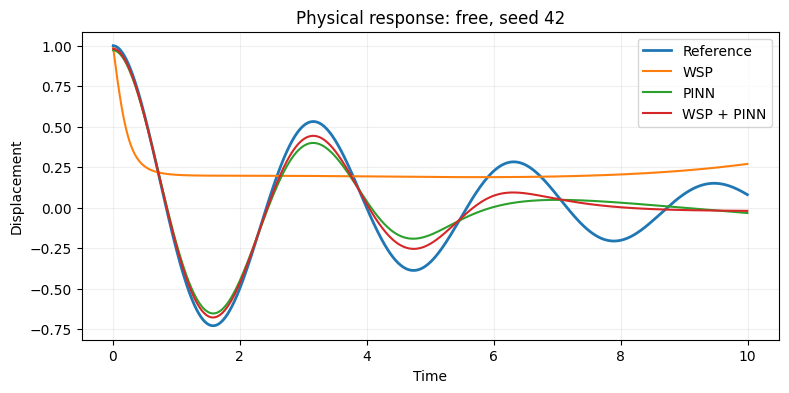

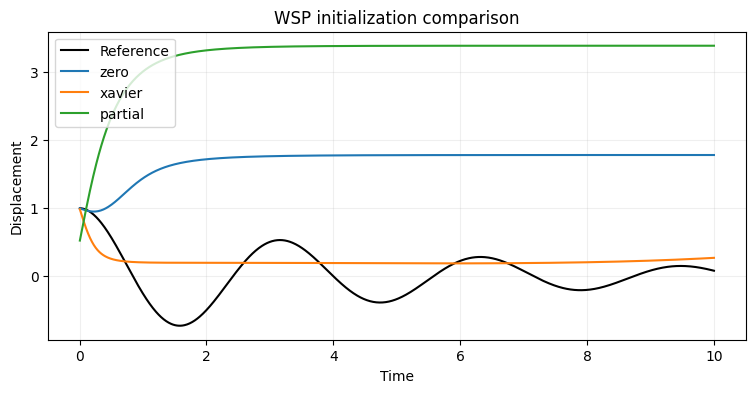

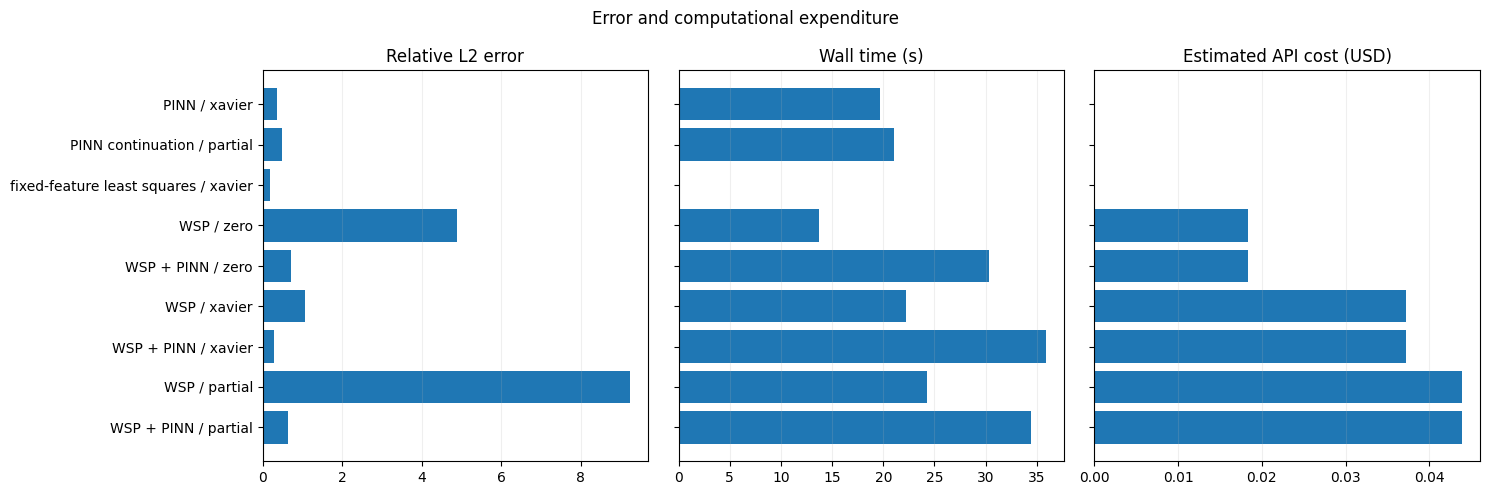

In [10]:
case=CASES[0]; seed=SEEDS[0]; t=THELD
def predict(model):
    with torch.no_grad(): return model(torch.tensor(t[:,None])).numpy().ravel()
fig,ax=plt.subplots(figsize=(9,4)); ax.plot(t,reference(t,case),label='Reference',lw=2)
for init,method in [('xavier','WSP'),('xavier','PINN'),('xavier','WSP + PINN')]: ax.plot(t,predict(models[(case,seed,init,method)]),label=method)
ax.set(xlabel='Time',ylabel='Displacement',title=f'Physical response: {case}, seed {seed}'); ax.legend(); ax.grid(alpha=.2); plt.show()
fig,ax=plt.subplots(figsize=(9,4)); ax.plot(t,reference(t,case),label='Reference',color='black')
for init in ['zero','xavier','partial']: ax.plot(t,predict(models[(case,seed,init,'WSP')]),label=init)
ax.set(xlabel='Time',ylabel='Displacement',title='WSP initialization comparison'); ax.legend(); ax.grid(alpha=.2); plt.show()
subset=[r for r in rows if r['configuration']==case and r['seed']==seed]; labels=[r['method']+' / '+r['initialization'] for r in subset]; y=np.arange(len(subset))
fig,axes=plt.subplots(1,3,figsize=(15,5),sharey=True)
for ax,key,title in zip(axes,['final_relative_l2','runtime_s','cost_usd'],['Relative L2 error','Wall time (s)','Estimated API cost (USD)']):
    ax.barh(y,[r[key] for r in subset]); ax.set_title(title); ax.grid(axis='x',alpha=.2)
axes[0].set_yticks(y,labels); axes[0].invert_yaxis(); fig.suptitle('Error and computational expenditure'); fig.tight_layout(); plt.show()


## Ten-seed PINN and least-squares follow-up
Moved from `ten_seed_baselines.py`, with seeds 42 through 51, the same optimizer,
steps and metrics. Set `RERUN_TEN_SEEDS=True` to retrain; new results go to
`wsp_rerun/ten_seed_baselines.json`, leaving historical results unchanged.
Notebook 2 reads the historical baseline file unless its `BASELINE_FILE` is changed.

In [ ]:
from common import metrics, EXTRA

def repeat_baselines(output_path):
    output_path.parent.mkdir(parents=True, exist_ok=True)
    records = []
    for seed in range(42, 52):
        pin = Net(seed)
        elapsed = train(pin, 'free', 3000)
        ls, ls_elapsed, _ = fixed_features(Net(seed), 'free')
        records.append({'seed': seed,
                        'PINN': {'heldout_0_10': metrics(pin, THELD), 'extrapolation_10_20': metrics(pin, EXTRA),
                                 'seconds': elapsed, 'physics_evaluations': 6000},
                        'least_squares': {'heldout_0_10': metrics(ls, THELD), 'extrapolation_10_20': metrics(ls, EXTRA),
                                          'seconds': ls_elapsed, 'physics_evaluations': 36}})
        output_path.write_text(json.dumps({'complete': len(records) == 10, 'trials': records}, indent=2), encoding='utf-8')
        print(f'Completed seed {seed}', flush=True)


In [ ]:
RERUN_TEN_SEEDS = False
baseline_path = HERE / 'iwsp_results' / 'ten_seed_baselines.json'
if RERUN_TEN_SEEDS:
    baseline_path = HERE / 'wsp_rerun' / 'ten_seed_baselines.json'
    repeat_baselines(baseline_path)
ten_seed_results = json.loads(baseline_path.read_text(encoding='utf-8'))
print('Complete:', ten_seed_results['complete'], '| baseline seeds:', len(ten_seed_results['trials']))